# Missing Value Imputation with Interpolation

**Interpolation** is a method of estimating missing values based on neighboring observed data points, assuming that the underlying process changes smoothly or continuously over an ordered dimension (such as time or distance).

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand the mathematical intuition behind **linear** and **time-weighted** interpolation.
2. Recognize the **critical domain requirement**: Interpolation is valid **ONLY for ordered / sequential data** (time series, sensor streams) and is **completely invalid for independent, cross-sectional tabular data**.
3. Compare linear interpolation against **forward fill (`ffill`)** and **backward fill (`bfill`)**.
4. Handle edge boundaries (leading/trailing NaNs) and constrain interpolation using the `limit` parameter.
5. Apply interpolation appropriately in Python with pandas and visualize the results.

---
## 1. When to Use (and When NEVER to Use) Interpolation

> ### ⚠️ Critical Machine Learning Warning:
> **Interpolation assumes an inherent ordering between adjacent rows.**
> - **VALID**: Time series (hourly weather, daily financial records, IoT sensor streams) and spatial data (elevation along a transect).
> - **INVALID**: Shuffled or cross-sectional data (e.g., customer databases, house prices, tabular survey responses). Interpolating between House #42 and House #43 is statistically meaningless because their row adjacency is purely arbitrary!

### Comparison of Sequential Imputation Strategies:
| Strategy | Method | Best Used When |
| :--- | :--- | :--- |
| **Linear Interpolation** | `df.interpolate(method='linear')` | Missing values lie between two known points in an evenly spaced sequence. |
| **Time Interpolation** | `df.interpolate(method='time')` | Timestamps are irregularly spaced (interpolates proportionally to elapsed time). |
| **Forward Fill (`ffill`)** | `df.ffill()` | Last known value persists until a new reading arrives (step function). |
| **Backward Fill (`bfill`)** | `df.bfill()` | Next known value is propagated backward (often used for leading edge NaNs). |

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Matplotlib styling
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 10

---
## 2. A Simple Intuition: Linear Interpolation

Linear interpolation draws a straight line between two known points $(x_0, y_0)$ and $(x_1, y_1)$ to estimate the missing value at $x$:

$$y = y_0 + (x - x_0) \frac{y_1 - y_0}{x_1 - x_0}$$

Let's begin with a simple 5-day daily temperature series where Day 3 is missing.

In [2]:
# Basic 5-day example
toy_df = pd.DataFrame({
    'Day': [1, 2, 3, 4, 5],
    'Temperature': [20.0, 22.0, np.nan, 26.0, 28.0]
})

print("Original Data with Missing Day 3:")
toy_df

Original Data with Missing Day 3:


,Day,Temperature
0,1,20.0
1,2,22.0
2,3,NaN
3,4,26.0
4,5,28.0


In [3]:
# Perform linear interpolation
toy_df['Temperature_Linear'] = toy_df['Temperature'].interpolate(method='linear')

print("After Linear Interpolation (Day 3 estimated as midpoint 24.0):")
toy_df

After Linear Interpolation (Day 3 estimated as midpoint 24.0):


,Day,Temperature,Temperature_Linear
0,1,20.0,20.0
1,2,22.0,22.0
2,3,NaN,24.0
3,4,26.0,26.0
4,5,28.0,28.0


---
## 3. Real-World Scenario: Time-Series Sensor Stream

Let's simulate a realistic 24-hour hourly IoT temperature sensor dataset with:
- Natural diurnal (day/night) temperature fluctuations.
- A short gap of missing readings (sensor transmission dropout).
- A longer gap of missing readings.

In [4]:
# Generate a 24-hour time series
np.random.seed(42)
dates = pd.date_range('2026-06-01 00:00', periods=24, freq='h')

# True underlying temperature: smooth sine wave + small noise
true_temp = 20 + 8 * np.sin(np.linspace(0, 2 * np.pi, 24)) + np.random.normal(0, 0.3, 24)

sensor_df = pd.DataFrame({
    'Timestamp': dates,
    'TrueTemp': true_temp,
    'ObservedTemp': true_temp.copy()
}).set_index('Timestamp')

# Introduce missing values: hours 5-6 (2 missing), hours 13-15 (3 missing)
sensor_df.loc['2026-06-01 05:00':'2026-06-01 06:00', 'ObservedTemp'] = np.nan
sensor_df.loc['2026-06-01 13:00':'2026-06-01 15:00', 'ObservedTemp'] = np.nan

print(f"Total readings: {len(sensor_df)}, Missing readings: {sensor_df['ObservedTemp'].isnull().sum()}")
sensor_df.head(10)

Total readings: 24, Missing readings: 5


,TrueTemp,ObservedTemp
Timestamp,,
2026-06-01 00:00:00,20.149014,20.149014
2026-06-01 01:00:00,22.116895,22.116895
2026-06-01 02:00:00,24.350978,24.350978
2026-06-01 03:00:00,26.303597,26.303597
2026-06-01 04:00:00,27.032836,27.032836
2026-06-01 05:00:00,27.762432,NaN
2026-06-01 06:00:00,28.455114,NaN
2026-06-01 07:00:00,27.768318,27.768318
2026-06-01 08:00:00,26.394917,26.394917


---
## 4. Comparing Imputation Methods: Linear vs. Forward Fill vs. Backward Fill

Let's compare:
1. `interpolate(method='linear')`: Linear interpolation between surrounding points.
2. `ffill()`: Propagates the last known measurement forward.
3. `bfill()`: Propagates the next known measurement backward.

In [5]:
# Apply different strategies
sensor_df['Linear_Interp'] = sensor_df['ObservedTemp'].interpolate(method='linear')
sensor_df['Forward_Fill']  = sensor_df['ObservedTemp'].ffill()
sensor_df['Backward_Fill'] = sensor_df['ObservedTemp'].bfill()

# Display rows around the missing period (04:00 to 07:00)
sensor_df.loc['2026-06-01 04:00':'2026-06-01 07:00']

,TrueTemp,ObservedTemp,Linear_Interp,Forward_Fill,Backward_Fill
Timestamp,,,,,
2026-06-01 04:00:00,27.032836,27.032836,27.032836,27.032836,27.032836
2026-06-01 05:00:00,27.762432,NaN,27.277996,27.032836,27.768318
2026-06-01 06:00:00,28.455114,NaN,27.523157,27.032836,27.768318
2026-06-01 07:00:00,27.768318,27.768318,27.768318,27.768318,27.768318


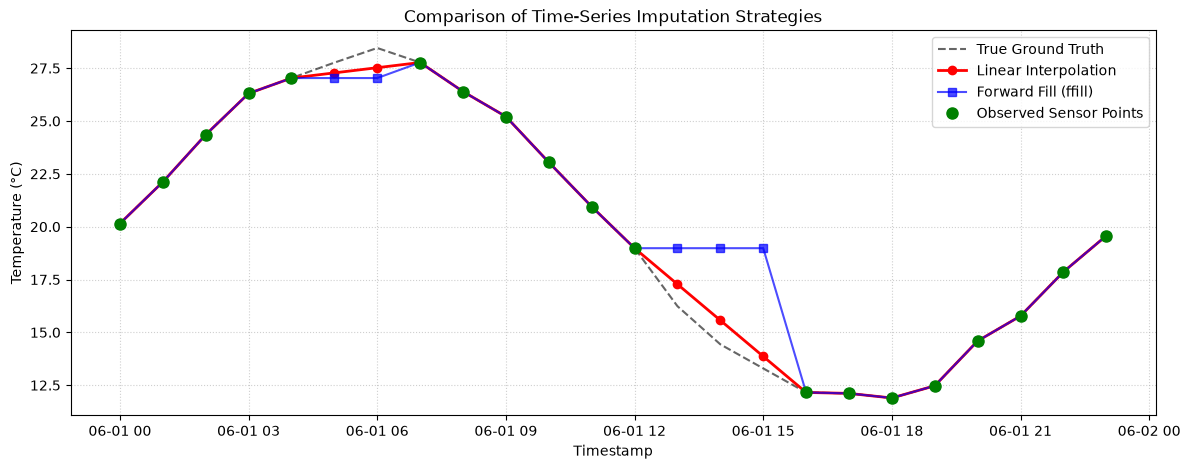

In [6]:
# Visualize the three imputation techniques against the true values
fig, ax = plt.subplots(figsize=(14, 5))

# Plot True and Observed
ax.plot(sensor_df.index, sensor_df['TrueTemp'], 'k--', label='True Ground Truth', alpha=0.6, lw=1.5)
ax.plot(sensor_df.index, sensor_df['Linear_Interp'], 'r-o', label='Linear Interpolation', lw=2)
ax.plot(sensor_df.index, sensor_df['Forward_Fill'], 'b-s', label='Forward Fill (ffill)', lw=1.5, alpha=0.7)
ax.plot(sensor_df.index, sensor_df['ObservedTemp'], 'go', markersize=8, label='Observed Sensor Points')

ax.set_title('Comparison of Time-Series Imputation Strategies')
ax.set_ylabel('Temperature (°C)')
ax.set_xlabel('Timestamp')
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Observation:
- **Linear interpolation** closely tracks the smooth true trajectory between missing points.
- **Forward fill** creates rigid step functions that underestimate rising trends and overestimate falling trends.

---
## 5. Handling Edge Boundaries & Limiting Gap Size

### 1. Leading and Trailing NaNs
Interpolation cannot extrapolate beyond known bounds. If the very first reading is NaN, `interpolate()` leaves it as NaN. The standard practice is to chain `.bfill()` or `.ffill()`:
```python
df['col'] = df['col'].interpolate(method='linear').bfill().ffill()
```

### 2. Restricting Gap Sizes with `limit`
If a sensor drops offline for 48 consecutive hours, linearly interpolating across such a massive blackout is dangerous. We can specify `limit=N` to only impute short, trustworthy gaps.

In [7]:
# Demonstrate boundary NaNs and limit parameter
gap_demo = pd.Series([np.nan, 10.0, np.nan, np.nan, np.nan, 20.0, np.nan])
print("Original Series with edge and interior NaNs:")
print(gap_demo.values)

# Interpolate with a maximum limit of 1 consecutive step
limited_interp = gap_demo.interpolate(method='linear', limit=1)
print("\nAfter interpolate(limit=1): (Notice only the first interior NaN is filled)")
print(limited_interp.values)

# Full treatment: interpolate short gaps, then handle edge with bfill/ffill
clean_series = gap_demo.interpolate(method='linear').bfill().ffill()
print("\nAfter interpolate() + bfill() + ffill():")
print(clean_series.values)

Original Series with edge and interior NaNs:
[nan 10. nan nan nan 20. nan]

After interpolate(limit=1): (Notice only the first interior NaN is filled)
[ nan 10.  12.5  nan  nan 20.  20. ]

After interpolate() + bfill() + ffill():
[10.  10.  12.5 15.  17.5 20.  20. ]


---
## 6. Demonstration: Why Interpolation Fails on Cross-Sectional Data

To illustrate why interpolation is strictly for ordered sequences, let's see what happens if we apply it to unordered tabular data (like the Ames House Prices).

In [8]:
# Load sample house prices
data_path = '../datasets/houseprice.csv'
if not os.path.exists(data_path):
    data_path = 'https://raw.githubusercontent.com/cmps460s26/cmps460-content/refs/heads/main/examples/03.dp/datasets/houseprice.csv'

house_sample = pd.read_csv(data_path, usecols=['Id', 'LotFrontage']).head(15).copy()

# Interpolating LotFrontage on unordered houses:
house_sample['Interpolated_LotFrontage'] = house_sample['LotFrontage'].interpolate(method='linear')

print("Unordered House Data with Arbitrary Interpolation:")
house_sample

Unordered House Data with Arbitrary Interpolation:


,Id,LotFrontage,Interpolated_LotFrontage
0,1,65.0,65.0
1,2,80.0,80.0
2,3,68.0,68.0
3,4,60.0,60.0
4,5,84.0,84.0
5,6,85.0,85.0
6,7,75.0,75.0
7,8,NaN,63.0
8,9,51.0,51.0
9,10,50.0,50.0


### Why This is Wrong:
House #7 (row 7) has a missing `LotFrontage`. Row 6 is a house built in 1976 with a 75 ft lot; Row 8 is a house built in 1931 with a 50 ft lot in a completely different neighborhood. 
Interpolating between them assumes House #7 lies geographically or chronologically halfway between two randomly indexed houses in the spreadsheet! 

For cross-sectional tabular data, always prefer **Median Imputation** or **Model-based Imputation** (KNN/IterativeImputer).

---
## 7. Summary & Best Practices Checklist

| Consideration | Recommendation |
| :--- | :--- |
| **When to Use** | Strictly on **ordered, sequential, or time-series data** (hourly/daily sensors, financial prices, continuous trajectories). |
| **When NOT to Use** | Shuffled or independent cross-sectional tabular data (e.g. house sales, customer profiles). |
| **Method Choice** | Use `method='linear'` for regular intervals; use `method='time'` if timestamps have unequal spacing. |
| **Large Gaps** | Use `limit=N` to prevent extrapolating over extended sensor blackouts. |
| **Boundary NaNs** | Chain with `.bfill()` or `.ffill()` to handle leading or trailing missing points. |
